# Twitter Sentiment Analysis Dataset :
**Domain : NLP**

# Objective Of Project:

**"Build a machine learning model that c;lassiifes the sentiment of text data(Positive, Negetive or Neutral), Providing insights into Public Opinion or Customer feedback."**

# Feature Checklist :

* Load dataset and inspect class distribution (positive/negetive/netural counts)

* Text preprocessing pipline : Lowercase, punctuation removel, stopword removel, tokenisation, optional stemming/lemmatization

* Feature extraction : TF-TDF Vectorizer(explain its purpose in a markdown cell)

* Train/Test Split(80/20)

* Train at least 2 Classifiers: Navie Bayes + one of (SVM, Logistic Regression, or simple LSTM if Confortable with deep learning)

* Evaluation: Accuracy, precision, recall, F1-score, confusion matrix for each model

* Visualisation: bar chart of sentiment distribution in the dataset; WordCloud for each sentiment class

* Error analysis: show 5 examples the model misclassified and discuss why

* Conclusion: which model performed best and what real-world application could this serv?

# Import Libraries

In [32]:
from gettext import install
import warnings

import pip
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import nltk
import re
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer
%pip install wordcloud
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score,f1_score, precision_score, recall_score

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


# Load dataset and inspect class distribution (positive/negetive/netural counts)

In [2]:
# Read the CSV file into a DataFrame
df = pd.read_csv('twitter_training.csv')
df.head()

,Paragraph,Company,Sentiment,Tweet
0,2401,Borderlands,Positive,im getting on borderlands and i will murder yo...
1,2401,Borderlands,Positive,I am coming to the borders and I will kill you...
2,2401,Borderlands,Positive,im getting on borderlands and i will kill you ...
3,2401,Borderlands,Positive,im coming on borderlands and i will murder you...
4,2401,Borderlands,Positive,im getting on borderlands 2 and i will murder ...


In [3]:
# Check the shape of the DataFrame
df.shape

(74682, 4)

In [4]:
# Check the information of the DataFrame
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 74682 entries, 0 to 74681
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   Paragraph  74682 non-null  int64
 1   Company    74682 non-null  str  
 2   Sentiment  74682 non-null  str  
 3   Tweet      73996 non-null  str  
dtypes: int64(1), str(3)
memory usage: 11.4 MB


<Axes: xlabel='Sentiment'>

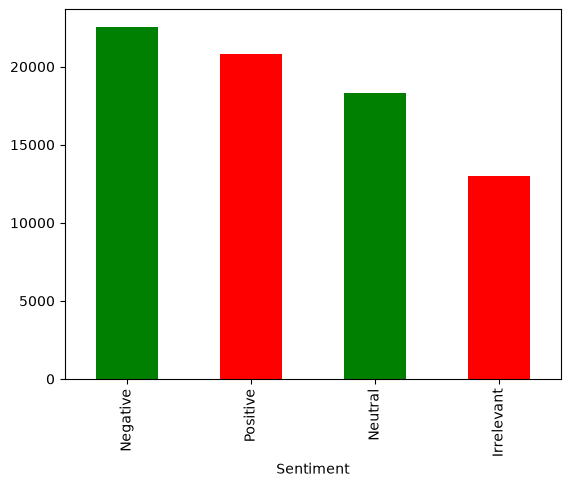

In [5]:
# Check Sentiment value counts
df['Sentiment'].value_counts().plot(kind='bar', color=['green', 'red'])

In [6]:
# Check Object type columns in the DataFrame
df.select_dtypes("object").columns

Index(['Company', 'Sentiment', 'Tweet'], dtype='str')

#  Text preprocessing pipline : 
**Lowercase, punctuation removel, stopword removel, tokenisation, optional stemming/lemmatization**

In [7]:
# Download required NLTK resources
for resource in ("stopwords", "punkt", "punkt_tab", "wordnet", "omw-1.4"):
    nltk.download(resource, quiet=True)

# Remove rows where Tweet is missing
df = df.dropna(subset=["Tweet"]).copy()

# Keep negation words because they affect sentiment
stop_words = set(stopwords.words("english")) - {"not", "no", "nor"}

lemmatizer = WordNetLemmatizer()
stemmer = PorterStemmer()

def preprocess_text(text, method="lemmatize"):
    text = str(text).lower()                              # Lowercase
    text = re.sub(r"https?://\S+|www\.\S+|@\w+", " ", text)  # Remove URLs and mentions
    text = re.sub(r"[^a-z\s]", " ", text)                # Remove punctuation/numbers
    tokens = nltk.word_tokenize(text)                    # Tokenisation
    tokens = [word for word in tokens if word not in stop_words]  # Stopword removal

    if method == "lemmatize":
        tokens = [lemmatizer.lemmatize(word) for word in tokens]
    elif method == "stem":
        tokens = [stemmer.stem(word) for word in tokens]

    return " ".join(tokens)

# Create cleaned tweet column
df["clean_tweet"] = df["Tweet"].apply(preprocess_text)

# View original and processed tweets
df[["Tweet", "clean_tweet"]].head()

,Tweet,clean_tweet
0,im getting on borderlands and i will murder yo...,im getting borderland murder
1,I am coming to the borders and I will kill you...,coming border kill
2,im getting on borderlands and i will kill you ...,im getting borderland kill
3,im coming on borderlands and i will murder you...,im coming borderland murder
4,im getting on borderlands 2 and i will murder ...,im getting borderland murder


### Preprocessing Explanation

        
        The tweets are cleaned before training the model. First, all text is converted to lowercase and URLs, mentions, punctuation, numbers, and special characters are removed. Then, each tweet is split into words using tokenization. Common stopwords such as “the”, “is”, and “and” are removed, while words like “not” are kept because they can change the sentiment. Finally, lemmatization or stemming converts words into their base form, and the cleaned text is saved in the `clean_tweet` column.

In [8]:
df["clean_tweet"] = df["Tweet"].apply(lambda x: preprocess_text(x, method="stem"))

# Feature extraction : 
        "TF-TDF Vectorizer(explain its purpose in a markdown cell)"


In [9]:
# Convert cleaned tweets into numerical TF-IDF features
tfidf = TfidfVectorizer(max_features=5000)

X = tfidf.fit_transform(df["clean_tweet"])

# Sentiment labels
y = df["Sentiment"]

print("Feature matrix shape:", X.shape)

Feature matrix shape: (73996, 5000)


# Train/Test Split(80/20) :

In [10]:
# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print("Training set shape:", X_train.shape)
print("Testing set shape:", X_test.shape)

Training set shape: (59196, 5000)
Testing set shape: (14800, 5000)


### Train-Test Split

The dataset is divided into 80% training data and 20% testing data. The training data is used to teach the model, while the testing data checks how well the trained model predicts sentiment for unseen tweets. `stratify=y` keeps the sentiment-class distribution similar in both sets.

# Train at least 2 Classifiers:
        "Navie Bayes + one of (SVM, Logistic Regression, or simple LSTM if Confortable with deep learning)"

In [11]:
# Model 1: Naive Bayes
naive_bayes_model = MultinomialNB()
naive_bayes_model.fit(X_train, y_train)

# Model 2: Logistic Regression
logistic_model = LogisticRegression(max_iter=1000, random_state=42)
logistic_model.fit(X_train, y_train)

# Predictions on test data
nb_predictions = naive_bayes_model.predict(X_test)
lr_predictions = logistic_model.predict(X_test)

### Model Training

Two classification models are trained using the TF-IDF features: Multinomial Naive Bayes and Logistic Regression. Both models learn from the training tweets and then predict the sentiment of the unseen test tweets.

# Evaluation:
**Accuracy, precision, recall, F1-score, confusion matrix for each model**

------ Naive Bayes ------
Accuracy : 0.6481
Precision: 0.664
Recall   : 0.6481
F1-Score : 0.6356

Classification Report:

              precision    recall  f1-score   support

  Irrelevant       0.76      0.35      0.48      2575
    Negative       0.62      0.82      0.71      4472
     Neutral       0.69      0.54      0.61      3622
    Positive       0.63      0.74      0.68      4131

    accuracy                           0.65     14800
   macro avg       0.67      0.61      0.62     14800
weighted avg       0.66      0.65      0.64     14800



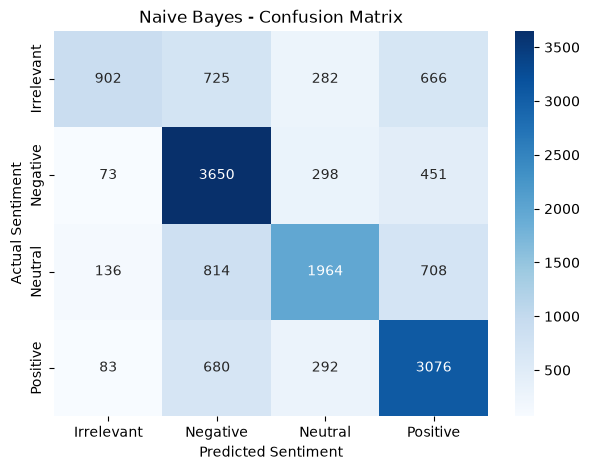

------ Logistic Regression ------
Accuracy : 0.6939
Precision: 0.6942
Recall   : 0.6939
F1-Score : 0.6901

Classification Report:

              precision    recall  f1-score   support

  Irrelevant       0.69      0.52      0.60      2575
    Negative       0.69      0.81      0.74      4472
     Neutral       0.70      0.64      0.67      3622
    Positive       0.69      0.73      0.71      4131

    accuracy                           0.69     14800
   macro avg       0.69      0.67      0.68     14800
weighted avg       0.69      0.69      0.69     14800



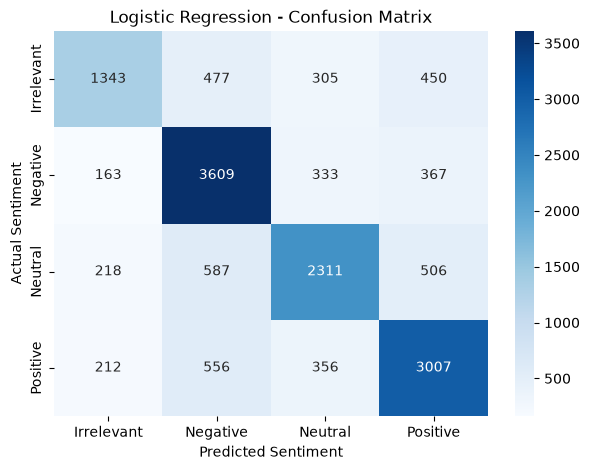

In [12]:
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, classification_report, confusion_matrix
)

# Function to evaluate each model
def evaluate_model(model_name, y_true, y_pred):
    print(f"------ {model_name} ------")
    print("Accuracy :", round(accuracy_score(y_true, y_pred), 4))
    print("Precision:", round(precision_score(y_true, y_pred, average="weighted", zero_division=0), 4))
    print("Recall   :", round(recall_score(y_true, y_pred, average="weighted", zero_division=0), 4))
    print("F1-Score :", round(f1_score(y_true, y_pred, average="weighted", zero_division=0), 4))

    print("\nClassification Report:\n")
    print(classification_report(y_true, y_pred, zero_division=0))

    # Confusion matrix
    labels = sorted(y_true.unique())
    cm = confusion_matrix(y_true, y_pred, labels=labels)

    plt.figure(figsize=(7, 5))
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues",
        xticklabels=labels, yticklabels=labels
    )
    plt.title(f"{model_name} - Confusion Matrix")
    plt.xlabel("Predicted Sentiment")
    plt.ylabel("Actual Sentiment")
    plt.show()

# Evaluate Naive Bayes
evaluate_model("Naive Bayes", y_test, nb_predictions)

# Evaluate Logistic Regression
evaluate_model("Logistic Regression", y_test, lr_predictions)

### Model Evaluation

Both models are evaluated using accuracy, precision, recall, and F1-score. The confusion matrix shows the number of correct and incorrect predictions for each sentiment class. Higher values for these metrics indicate better model performance.

# Visualisation : 
"Bar chart of sentiment distribution in the dataset; WordCloud for each sentiment class"

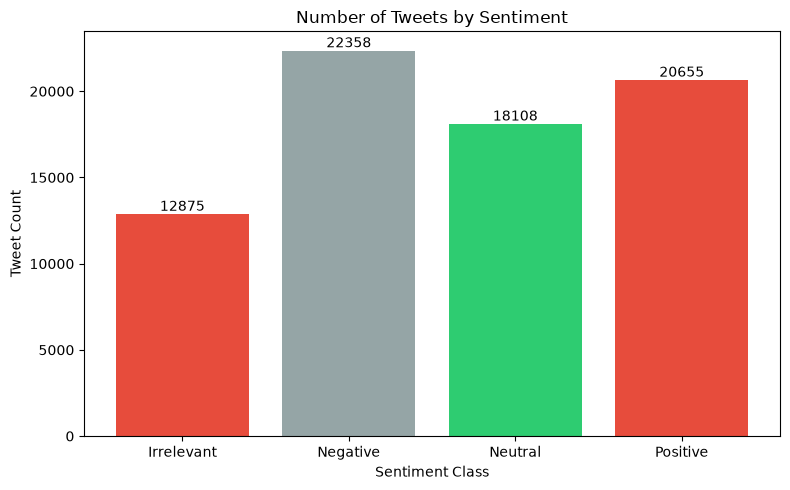

In [35]:
# Sentiment distribution bar chart
class_counts = df["Sentiment"].value_counts().sort_index()

colors = ["#e74c3c", "#95a5a6", "#2ecc71"]

plt.figure(figsize=(8, 5))
bars = plt.bar(class_counts.index, class_counts.values, color=colors[:len(class_counts)])

plt.title("Number of Tweets by Sentiment")
plt.xlabel("Sentiment Class")
plt.ylabel("Tweet Count")

for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        str(int(bar.get_height())),
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()

# Word cloud for each sentiment class :

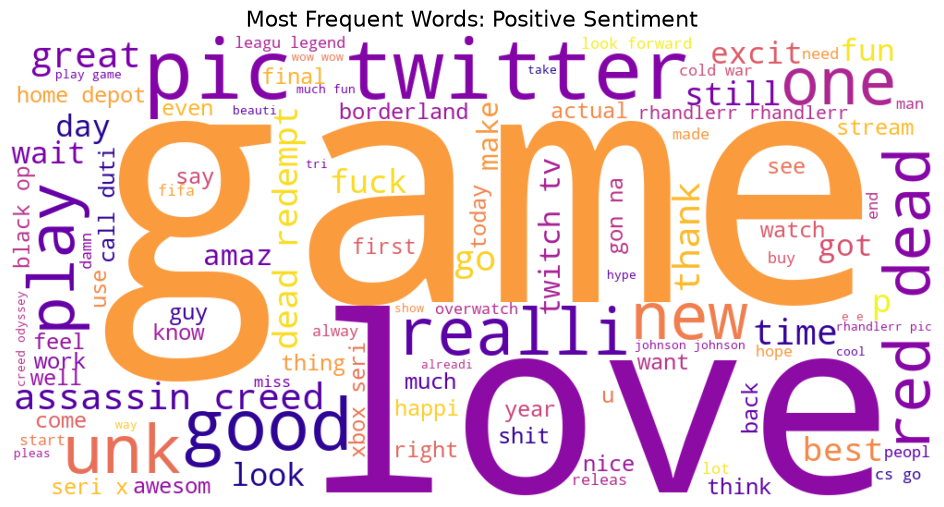

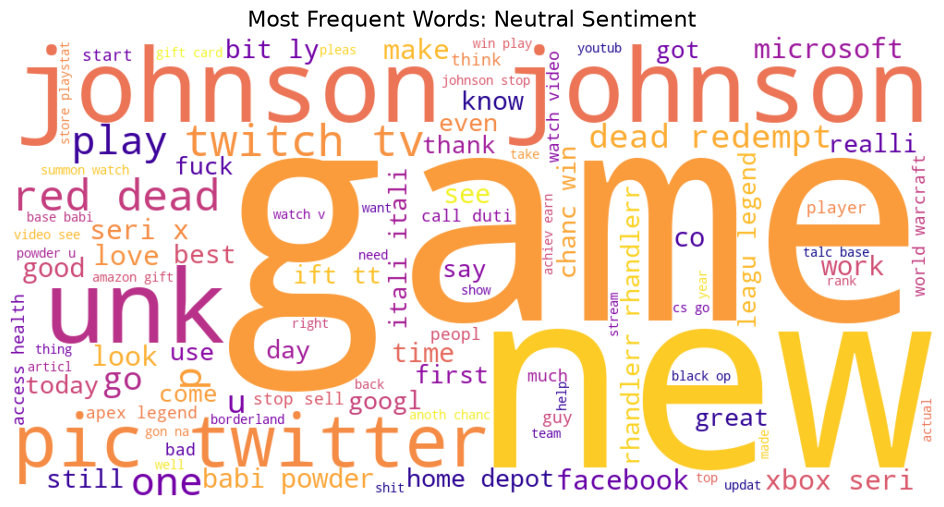

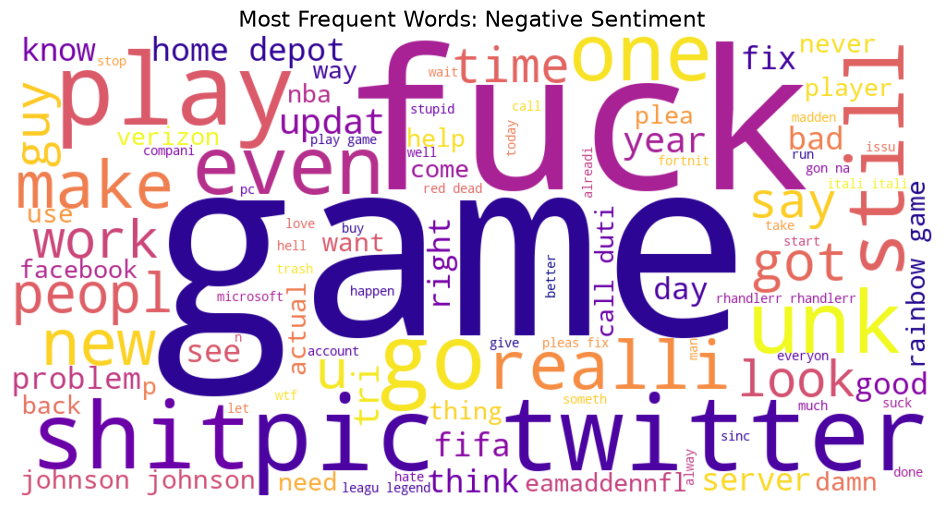

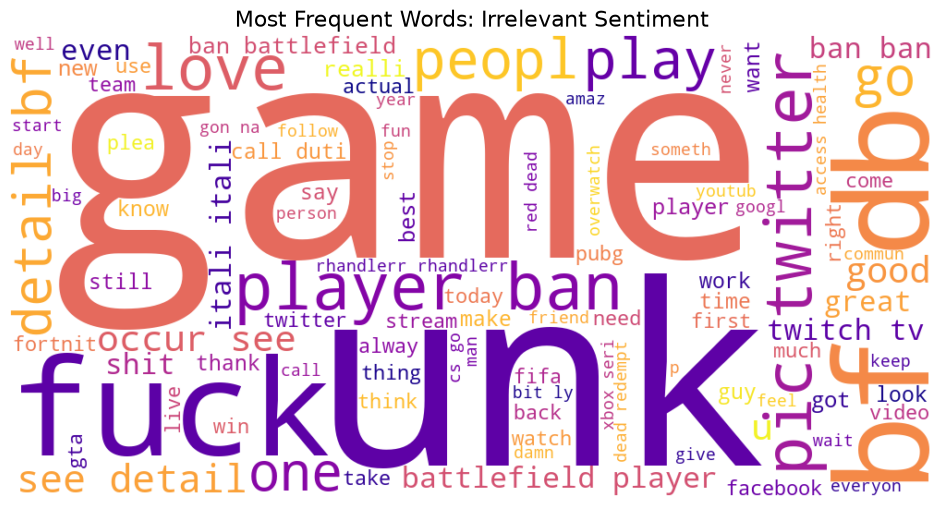

In [36]:
for sentiment in df["Sentiment"].dropna().unique():
    text = " ".join(
        df[df["Sentiment"] == sentiment]["clean_tweet"].dropna().astype(str)
    )

    cloud = WordCloud(
        width=1000,
        height=500,
        background_color="white",
        max_words=100,
        colormap="plasma"
    ).generate(text)

    plt.figure(figsize=(12, 6))
    plt.imshow(cloud, interpolation="bilinear")
    plt.title(f"Most Frequent Words: {sentiment} Sentiment", fontsize=16)
    plt.axis("off")
    plt.show()

### Positive Sentiment Word Cloud Explanation

This word cloud shows the most frequently used words in tweets labelled as **Positive**. Larger words, such as **“game”**, **“love”**, **“twitter”**, **“good”**, and **“great”**, appear more often in positive tweets. These words suggest that users are discussing games, enjoying content, or expressing positive opinions.

Some common words, such as **“twitter”**, may appear large because they occur frequently in the dataset, even if they do not directly represent positive sentiment. The word cloud helps identify important and repeated words within the positive sentiment class.

# Error analysis: 
**show 5 examples the model misclassified and discuss why**

In [37]:
# Error Analysis: 5 misclassified examples from Logistic Regression

# Match test rows with their original tweets
error_analysis = df.loc[y_test.index, ["Tweet", "Sentiment"]].copy()

# Add actual and predicted labels
error_analysis["Actual Sentiment"] = y_test.values
error_analysis["Predicted Sentiment"] = lr_predictions

# Keep only incorrect predictions
misclassified = error_analysis[
    error_analysis["Actual Sentiment"] != error_analysis["Predicted Sentiment"]
]

# Show five examples
misclassified[
    ["Tweet", "Actual Sentiment", "Predicted Sentiment"]
].head(5)

,Tweet,Actual Sentiment,Predicted Sentiment
60101,Real Real.,Irrelevant,Positive
9819,"Not unheard of, honestly. The concern I would ...",Negative,Positive
61700,The number of people begging for money from mo...,Irrelevant,Negative
29716,"The thing sure is brother, Apex Tower deserves...",Negative,Neutral
67344,@JNJCares good Luck! Hope lives go before prof...,Negative,Neutral


### Error Analysis

The misclassified tweets show cases where the model predicted a different sentiment from the actual label. This can happen because tweets are short, use informal language, contain sarcasm, mixed opinions, spelling mistakes, emojis, or context-dependent words. For example, a tweet may contain positive words but express a negative meaning through sarcasm. The TF-IDF model also treats words separately and may not fully understand the context or word order of a sentence.